<a href="https://colab.research.google.com/github/SamikshaDTawde-25/online-payment-fraud-detection/blob/main/Big_Data_Online_Payment_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Downloading the dataset**

In [ ]:
! pip install -q kaggle

In [ ]:
from google.colab import files

In [ ]:
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"samikshatawde","key":"df33a6bc7f0fd088b1412db2c7eeadd0"}'}

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp '/content/kaggle.json' '/content'

cp: '/content/kaggle.json' and '/content/kaggle.json' are the same file


In [ ]:
import zipfile
import os

os.environ['KAGGLE_CONFIG_DIR'] = "/content"

In [ ]:
!chmod 600 /content/kaggle.json

In [ ]:
!kaggle datasets download -d rupakroy/online-payments-fraud-detection-dataset

 99% 176M/178M [00:07<00:00, 35.0MB/s]
100% 178M/178M [00:07<00:00, 25.8MB/s]


In [ ]:
zip_ref1 = zipfile.ZipFile('/content/online-payments-fraud-detection-dataset.zip', 'r') #Opens the zip file in read mode
zip_ref1.extractall('/tmp') #Extracts the files into the /tmp folder
zip_ref1.close()

In [ ]:
os.listdir('/tmp')

['initgoogle_syslog_dir.0',
 'language_service.INFO',
 'PS_20174392719_1491204439457_log.csv',
 'language_service.6c2300155010.root.log.INFO.20230827-064941.317',
 'drive.WARNING',
 'directoryprefetcher_binary.6c2300155010.root.log.INFO.20230827-065526.1895',
 'pyright-343-5l2W4Po0bJ0c',
 'drive.6c2300155010.root.log.ERROR.20230827-065523.1794',
 'drive.6c2300155010.root.log.INFO.20230827-065523.1794',
 'drivefs_ipc.0_shell',
 'drive.6c2300155010.root.log.INFO.20230827-065516.1699',
 'python-languageserver-cancellation',
 'drive.INFO',
 'language_service.6c2300155010.root.log.INFO.20230827-064934.264',
 'debugger_2qjqyi53a',
 'directoryprefetcher_binary.INFO',
 'drive.ERROR',
 'dap_multiplexer.INFO',
 'drivefs_ipc.0',
 'drive.6c2300155010.root.log.INFO.20230827-065516.1702',
 'dap_multiplexer.6c2300155010.root.log.INFO.20230827-064902.80',
 'drive.6c2300155010.root.log.INFO.20230827-065523.1699',
 'drive.6c2300155010.root.log.WARNING.20230827-065523.1794',
 'pyright-343-A1LG0mUodkmb',


In [ ]:
import numpy as np
import pandas as pd
import string


import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import seaborn as sns
from keras import callbacks
from sklearn.metrics import accuracy_score
from os import listdir
from os.path import isfile, join

**Using PySpark**

In [ ]:
!pip install pyspark

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.8/310.8 MB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyspark: filename=pyspark-3.4.1-py2.py3-none-any.whl size=311285387 sha256=409abbac6ee3b4656d5b9578287d560e8b31f8baaef4d16ceaa6b31e8c44e356
  Stored in directory: /root/.cache/pip/wheels/0d/77/a3/ff2f74cc9ab41f8f594dabf0579c2a7c6de920d584206e0834
Successfully built pyspark


In [ ]:
import pyspark as spark

In [ ]:
from pyspark import SparkContext, SQLContext

In [ ]:
sc=SparkContext()

In [ ]:
sqc=SQLContext(sc)

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:112: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
sparkdf=sqc.read.csv('/tmp/PS_20174392719_1491204439457_log.csv')

In [ ]:
#To show the dataframe
sparkdf.show()

+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
| _c0|     _c1|      _c2|        _c3|          _c4|           _c5|        _c6|           _c7|           _c8|    _c9|          _c10|
+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|   amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
|   1| PAYMENT|  9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT|  1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|    181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|    181.0| C840083671|        181.0|           0.0|  C3899701

In [ ]:
#With headers
sparkdf=sqc.read.options(header=True).csv('/tmp/PS_20174392719_1491204439457_log.csv')

In [ ]:
sparkdf.show()

+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|   amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
+----+--------+---------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|   1| PAYMENT|  9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT|  1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|    181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|    181.0| C840083671|        181.0|           0.0|  C38997010|       21182.0|           0.0|      1|             0|
|   1| PAYMENT| 11668.14|C2048537720|      41554.0|      29885.86|M123070170

In [ ]:
#To show only the top 5
sparkdf.show(5)

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|  amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|   1| PAYMENT| 9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT| 1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|   181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|   181.0| C840083671|        181.0|           0.0|  C38997010|       21182.0|           0.0|      1|             0|
|   1| PAYMENT|11668.14|C2048537720|      41554.0|      29885.86|M1230701703|      

In [ ]:
#Just like the loc function pandas
sparkdf.select('type').show()

+--------+
|    type|
+--------+
| PAYMENT|
| PAYMENT|
|TRANSFER|
|CASH_OUT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
|   DEBIT|
|   DEBIT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
|CASH_OUT|
| PAYMENT|
| PAYMENT|
| PAYMENT|
|TRANSFER|
+--------+
only showing top 20 rows



In [ ]:
#Just like the loc function pandas
sparkdf.select(['type','nameOrig']).show(5)

+--------+-----------+
|    type|   nameOrig|
+--------+-----------+
| PAYMENT|C1231006815|
| PAYMENT|C1666544295|
|TRANSFER|C1305486145|
|CASH_OUT| C840083671|
| PAYMENT|C2048537720|
+--------+-----------+
only showing top 5 rows



In [ ]:
sparkdf.printSchema()

root
 |-- step: string (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: string (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: string (nullable = true)
 |-- newbalanceOrig: string (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: string (nullable = true)
 |-- newbalanceDest: string (nullable = true)
 |-- isFraud: string (nullable = true)
 |-- isFlaggedFraud: string (nullable = true)



In [ ]:
sparkdf.dtypes  #To get datatypes as a list of tuples

[('step', 'string'),
 ('type', 'string'),
 ('amount', 'string'),
 ('nameOrig', 'string'),
 ('oldbalanceOrg', 'string'),
 ('newbalanceOrig', 'string'),
 ('nameDest', 'string'),
 ('oldbalanceDest', 'string'),
 ('newbalanceDest', 'string'),
 ('isFraud', 'string'),
 ('isFlaggedFraud', 'string')]

In [ ]:
#The dtypes do not match with our requirement
#So changing the schema

newsparkdf=sqc.read.csv('/tmp/PS_20174392719_1491204439457_log.csv', inferSchema=True,header=True)

In [ ]:
newsparkdf.show(5)

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|  amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|   1| PAYMENT| 9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT| 1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|   181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|   181.0| C840083671|        181.0|           0.0|  C38997010|       21182.0|           0.0|      1|             0|
|   1| PAYMENT|11668.14|C2048537720|      41554.0|      29885.86|M1230701703|      

In [ ]:
newsparkdf.printSchema()

root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)



In [ ]:
#The above datatypes now somewhat match the datatypes in pandas
#only object is converted to string and
#float is converted to double

In [ ]:
#Finding names of columns with dtype as double
for col in newsparkdf.dtypes:
  if(col[1]=='double'):
    print(col[0])

amount
oldbalanceOrg
newbalanceOrig
oldbalanceDest
newbalanceDest


In [ ]:
#Changing the double datatype into float datatypes

from pyspark.sql.types import FloatType
newsparkdf=newsparkdf.withColumn("amount",newsparkdf.amount.cast(FloatType()))
newsparkdf=newsparkdf.withColumn("oldbalanceOrg",newsparkdf.oldbalanceOrg.cast(FloatType()))
newsparkdf=newsparkdf.withColumn("newbalanceOrig",newsparkdf.newbalanceOrig.cast(FloatType()))
newsparkdf=newsparkdf.withColumn("oldbalanceDest",newsparkdf.oldbalanceDest.cast(FloatType()))
newsparkdf=newsparkdf.withColumn("newbalanceDest",newsparkdf.newbalanceDest.cast(FloatType()))

In [ ]:
newsparkdf.dtypes

[('step', 'int'),
 ('type', 'string'),
 ('amount', 'float'),
 ('nameOrig', 'string'),
 ('oldbalanceOrg', 'float'),
 ('newbalanceOrig', 'float'),
 ('nameDest', 'string'),
 ('oldbalanceDest', 'float'),
 ('newbalanceDest', 'float'),
 ('isFraud', 'int'),
 ('isFlaggedFraud', 'int')]

In [ ]:
#Changing the Column names
col_name_pairs=[('step','Step'),
                ('type','Type'),
                ('amount','Amount'),
                ('nameOrig','NameOrig'),
                ('oldbalanceOrg','OldbalanceOrg'),
                ('newbalanceOrig','NewbalanceOrig'),
                ('nameDest','NameDest'),
                ('oldbalanceDest','OldbalanceDest'),
                ('newbalanceDest','NewbalanceDest'),
                ('isFraud','IsFraud'),
                ('isFlaggedFraud','IsFlaggedFraud')
               ]

for old_name,new_name in col_name_pairs:
  newsparkdf=newsparkdf.withColumnRenamed(old_name,new_name)

In [ ]:
for col in newsparkdf.dtypes:     #Names of the columns
   print(col[0])

Step
Type
Amount
NameOrig
OldbalanceOrg
NewbalanceOrig
NameDest
OldbalanceDest
NewbalanceDest
IsFraud
IsFlaggedFraud


In [ ]:
newsparkdf

DataFrame[Step: int, Type: string, Amount: float, NameOrig: string, OldbalanceOrg: float, NewbalanceOrig: float, NameDest: string, OldbalanceDest: float, NewbalanceDest: float, IsFraud: int, IsFlaggedFraud: int]

In [ ]:
#Describing the dataframe
newsparkdf.select(['Step','Amount','OldbalanceOrg','NewbalanceOrig',
                  'OldbalanceDest','NewbalanceDest','IsFraud','IsFlaggedFraud']).describe().show()

+-------+------------------+-----------------+------------------+-----------------+------------------+-----------------+--------------------+--------------------+
|summary|              Step|           Amount|     OldbalanceOrg|   NewbalanceOrig|    OldbalanceDest|   NewbalanceDest|             IsFraud|      IsFlaggedFraud|
+-------+------------------+-----------------+------------------+-----------------+------------------+-----------------+--------------------+--------------------+
|  count|           6362620|          6362620|           6362620|          6362620|           6362620|          6362620|             6362620|             6362620|
|   mean|243.39724563151657|179861.9035579989| 833883.1040482761|855113.6685519279|1100701.6665156623|1224996.398184315|0.001290820448180152| 2.51468734577894E-6|
| stddev|142.33197104913066|603858.2316772637|2888242.6729989178|2924048.502910317|3399180.1117577194|3674128.941013759|0.035904796801604424|0.001585774705736...|
|    min|             

In [ ]:
# Find Count of Null, None, NaN of the DataFrame Columns
from pyspark.sql.functions import col,isnan, when, count
newsparkdf.select([count(when(isnan(c) | col(c).isNull(), c)).alias(c) for c in newsparkdf.columns]
   ).show()


+----+----+------+--------+-------------+--------------+--------+--------------+--------------+-------+--------------+
|Step|Type|Amount|NameOrig|OldbalanceOrg|NewbalanceOrig|NameDest|OldbalanceDest|NewbalanceDest|IsFraud|IsFlaggedFraud|
+----+----+------+--------+-------------+--------------+--------+--------------+--------------+-------+--------------+
|   0|   0|     0|       0|            0|             0|       0|             0|             0|      0|             0|
+----+----+------+--------+-------------+--------------+--------+--------------+--------------+-------+--------------+



In [ ]:
#Dropping the null values
newsparkdf=newsparkdf.na.drop()

Dropping the names column and IsFlaggedFraud column

In [ ]:
modsparkdf=newsparkdf.drop('NameOrig','NameDest','IsFlaggedFraud')

In [ ]:
modsparkdf.show(5)

+----+--------+--------+-------------+--------------+--------------+--------------+-------+
|Step|    Type|  Amount|OldbalanceOrg|NewbalanceOrig|OldbalanceDest|NewbalanceDest|IsFraud|
+----+--------+--------+-------------+--------------+--------------+--------------+-------+
|   1| PAYMENT| 9839.64|     170136.0|     160296.36|           0.0|           0.0|      0|
|   1| PAYMENT| 1864.28|      21249.0|      19384.72|           0.0|           0.0|      0|
|   1|TRANSFER|   181.0|        181.0|           0.0|           0.0|           0.0|      1|
|   1|CASH_OUT|   181.0|        181.0|           0.0|       21182.0|           0.0|      1|
|   1| PAYMENT|11668.14|      41554.0|      29885.86|           0.0|           0.0|      0|
+----+--------+--------+-------------+--------------+--------------+--------------+-------+
only showing top 5 rows



In [ ]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(inputCol="Type", outputCol="Type_label")
indexed_df = indexer.fit(modsparkdf).transform(modsparkdf)
indexed_df=indexed_df.drop("Type").withColumnRenamed("Type_label","Type")
print("The output dataframe is:")
indexed_df.show()
#spark.sparkContext.stop()

The output dataframe is:
+----+---------+-------------+--------------+--------------+--------------+-------+----+
|Step|   Amount|OldbalanceOrg|NewbalanceOrig|OldbalanceDest|NewbalanceDest|IsFraud|Type|
+----+---------+-------------+--------------+--------------+--------------+-------+----+
|   1|  9839.64|     170136.0|     160296.36|           0.0|           0.0|      0| 1.0|
|   1|  1864.28|      21249.0|      19384.72|           0.0|           0.0|      0| 1.0|
|   1|    181.0|        181.0|           0.0|           0.0|           0.0|      1| 3.0|
|   1|    181.0|        181.0|           0.0|       21182.0|           0.0|      1| 0.0|
|   1| 11668.14|      41554.0|      29885.86|           0.0|           0.0|      0| 1.0|
|   1|  7817.71|      53860.0|      46042.29|           0.0|           0.0|      0| 1.0|
|   1|  7107.77|     183195.0|     176087.23|           0.0|           0.0|      0| 1.0|
|   1|  7861.64|    176087.23|      168225.6|           0.0|           0.0|      0| 1

In [ ]:
X_col_names=['Step','Amount','OldbalanceOrg','NewbalanceOrig','OldbalanceDest','NewbalanceDest','Type']

In [ ]:
from pyspark.ml.feature import VectorAssembler

v_asmblr=VectorAssembler(inputCols=X_col_names,outputCol='Features')

In [ ]:
df=v_asmblr.transform(indexed_df)

In [ ]:
df.select("features","IsFraud").show(5)

+--------------------+-------+
|            features|IsFraud|
+--------------------+-------+
|[1.0,9839.6396484...|      0|
|[1.0,1864.2800292...|      0|
|[1.0,181.0,181.0,...|      1|
|[1.0,181.0,181.0,...|      1|
|[1.0,11668.139648...|      0|
+--------------------+-------+
only showing top 5 rows



In [ ]:
train, test = df.randomSplit([0.8, 0.2], seed=17)

**For Logistic Regression**

In [ ]:
from pyspark.ml.classification import LogisticRegression
lr = LogisticRegression(featuresCol = 'Features', labelCol = 'IsFraud', maxIter=10)
lrModel = lr.fit(train)

In [ ]:
lrpredictions = lrModel.transform(test)
lrpredictions.show(5)

+----+------+-------------+--------------+--------------+--------------+-------+----+--------------------+--------------------+--------------------+----------+
|Step|Amount|OldbalanceOrg|NewbalanceOrig|OldbalanceDest|NewbalanceDest|IsFraud|Type|            Features|       rawPrediction|         probability|prediction|
+----+------+-------------+--------------+--------------+--------------+-------+----+--------------------+--------------------+--------------------+----------+
|   1|  6.42|     18462.78|      18456.36|           0.0|           0.0|      0| 1.0|[1.0,6.4200000762...|[8.78922140230939...|[0.99984765665826...|       0.0|
|   1| 25.12|      61663.0|      61637.88|           0.0|           0.0|      0| 1.0|[1.0,25.120000839...|[8.80003052043089...|[0.99984929424092...|       0.0|
|   1| 58.21|      14506.0|      14447.79|           0.0|           0.0|      0| 1.0|[1.0,58.209999084...|[8.78805214803515...|[0.99984747845317...|       0.0|
|   1|137.88|     59708.34|      59570.4

In [ ]:
# Make predicitons
lrpredictionAndTarget = lrpredictions.select("IsFraud", "prediction")

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
multievaluator = MulticlassClassificationEvaluator()
multievaluator.setLabelCol("IsFraud")
multievaluator.setPredictionCol("prediction")

MulticlassClassificationEvaluator_c36f533b53ff

In [ ]:
print("Test Area under ROC for LR for Multievaluator: " ,multievaluator.evaluate(lrpredictions))

Test Area under ROC for LR for Multievaluator:  0.9986184138536152


In [ ]:
"""When 0.5<AUC<1, there is a high chance that the classifier will be able to distinguish the positive class values from the negative ones.
This is so because the classifier is able to detect more numbers of True positives and True negatives than False negatives and False positives."""

'When 0.5<AUC<1, there is a high chance that the classifier will be able to distinguish the positive class values from the negative ones.\nThis is so because the classifier is able to detect more numbers of True positives and True negatives than False negatives and False positives.'

In [ ]:
# Get metrics
lracc = multievaluator.evaluate(lrpredictionAndTarget, {multievaluator.metricName: "accuracy"})
lrf1 = multievaluator.evaluate(lrpredictionAndTarget, {multievaluator.metricName: "f1"})
lrweightedPrecision = multievaluator.evaluate(lrpredictionAndTarget, {multievaluator.metricName: "weightedPrecision"})
lrweightedRecall = multievaluator.evaluate(lrpredictionAndTarget, {multievaluator.metricName: "weightedRecall"})

In [ ]:
lrmroc =multievaluator.evaluate(lrpredictions)

In [ ]:
print("Logistic Regression")
print("Accuracy : ", lracc)
print("F1Score : ", lrf1)
print("WeightedPrecision : ", lrweightedPrecision )
print("WeightedRecall: ", lrweightedRecall )

Logistic Regression
Accuracy :  0.9989699396813648
F1Score :  0.9986184138536152
WeightedPrecision :  0.9989405016704803
WeightedRecall:  0.9989699396813648


Plotting the ROC curve

In [ ]:
lrtrainingSummary = lrModel.summary
lrroc = lrtrainingSummary.roc.toPandas()

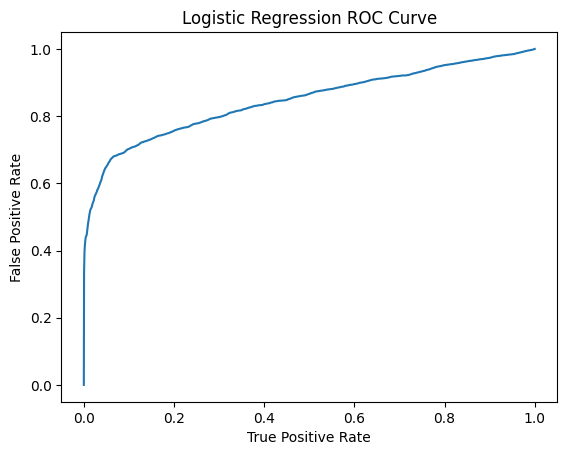

In [ ]:
#The roc DataFrame now contains the FPR and TPR for various threshold settings. You can visualize it using matplotlib:

import matplotlib.pyplot as plt

plt.plot(lrroc['FPR'],lrroc['TPR'])
plt.ylabel('False Positive Rate')
plt.xlabel('True Positive Rate')
plt.title('Logistic Regression ROC Curve')
plt.show()

**For Random Forest**

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

# Define and fit the RandomForestClassifier model
rf = RandomForestClassifier(featuresCol='Features', labelCol='IsFraud', numTrees=10)
rfModel = rf.fit(train)

# Use the model to make predictions on test data
rfpredictions = rfModel.transform(test)

# Select relevant columns from the predictions DataFrame
rfpredictionAndTarget = rfpredictions.select("IsFraud", "prediction")

In [ ]:
rfmroc=multievaluator.evaluate(rfpredictions)

In [ ]:
print("Test Area under ROC for rf for Multievaluator : " ,rfmroc)

Test Area under ROC for rf for Multievaluator :  0.9993057848555067


In [ ]:
# Get metrics
rfacc = multievaluator.evaluate(rfpredictionAndTarget, {multievaluator.metricName: "accuracy"})
rff1 = multievaluator.evaluate(rfpredictionAndTarget, {multievaluator.metricName: "f1"})
rfweightedPrecision = multievaluator.evaluate(rfpredictionAndTarget, {multievaluator.metricName: "weightedPrecision"})
rfweightedRecall = multievaluator.evaluate(rfpredictionAndTarget, {multievaluator.metricName: "weightedRecall"})

In [ ]:
print("Random Forest")
print("Accuracy:", rfacc)
print("F1Score:", rff1)
print("WeightedPrecision:", rfweightedPrecision)
print("WeightedRecall:", rfweightedRecall)

Random Forest
Accuracy: 0.9993997207601547
F1Score: 0.9993057848555067
WeightedPrecision: 0.9993986448036628
WeightedRecall: 0.9993997207601546


In [ ]:
rftrainingSummary = rfModel.summary
rfroc = rftrainingSummary.roc.toPandas()

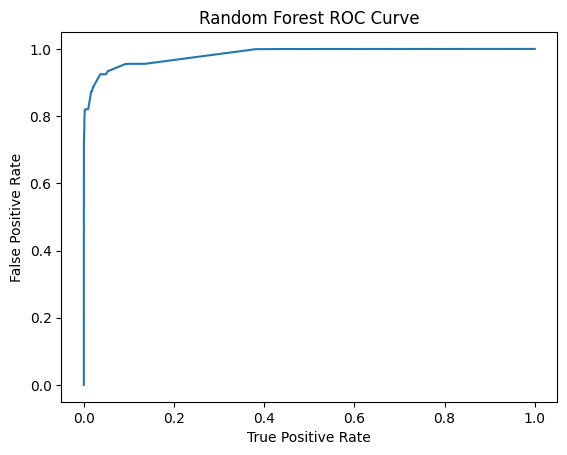

In [ ]:
plt.plot(rfroc['FPR'],rfroc['TPR'])
plt.ylabel('False Positive Rate')
plt.xlabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.show()

**For Decision Tree**

In [ ]:
from pyspark.ml.classification import DecisionTreeClassifier

dt = DecisionTreeClassifier(featuresCol='Features', labelCol='IsFraud')
dtModel = dt.fit(train)
dtpredictions = dtModel.transform(test)

In [ ]:
dtmroc=multievaluator.evaluate(dtpredictions)

In [ ]:
print("Test Area under ROC for dt for Multievaluator: " ,dtmroc)

Test Area under ROC for dt for Multievaluator:  0.9993608338435384


In [ ]:
# Make predicitons
dtpredictionAndTarget = dtpredictions.select("IsFraud", "prediction")

In [ ]:
# Get metrics
dtacc = multievaluator.evaluate(dtpredictionAndTarget, {multievaluator.metricName: "accuracy"})
dtf1 = multievaluator.evaluate(dtpredictionAndTarget, {multievaluator.metricName: "f1"})
dtweightedPrecision = multievaluator.evaluate(dtpredictionAndTarget, {multievaluator.metricName: "weightedPrecision"})
dtweightedRecall = multievaluator.evaluate(dtpredictionAndTarget, {multievaluator.metricName: "weightedRecall"})

In [ ]:
print("Decision Tree")
print("Accuracy : ", dtacc)
print("F1Score : ", dtf1)
print("WeightedPrecision : ", dtweightedPrecision )
print("WeightedRecall: ", dtweightedRecall )

Decision Tree
Accuracy :  0.9993863637613623
F1Score :  0.9993608338435384
WeightedPrecision :  0.9993481703326312
WeightedRecall:  0.9993863637613624


**For Naive Bayes**

In [ ]:
from pyspark.ml.classification import NaiveBayes
nb = NaiveBayes(featuresCol='Features', labelCol='IsFraud')
nbModel = nb.fit(train)
nbpredictions = nbModel.transform(test)

In [ ]:
nbmroc=multievaluator.evaluate(nbpredictions)

In [ ]:
print("Test Area under ROC for nb for Multievaluator: " ,nbmroc)

Test Area under ROC for nb for Multievaluator:  0.7676738154946054


In [ ]:
# Make predicitons
nbpredictionAndTarget = nbpredictions.select("IsFraud", "prediction")

In [ ]:
# Get metrics
nbacc = multievaluator.evaluate(nbpredictionAndTarget, {multievaluator.metricName: "accuracy"})
nbf1 = multievaluator.evaluate(nbpredictionAndTarget, {multievaluator.metricName: "f1"})
nbweightedPrecision = multievaluator.evaluate(nbpredictionAndTarget, {multievaluator.metricName: "weightedPrecision"})
nbweightedRecall = multievaluator.evaluate(nbpredictionAndTarget, {multievaluator.metricName: "weightedRecall"})

In [ ]:
print("Naive Bayes Tree")
print("Accuracy : ", nbacc)
print("F1Score : ", nbf1)
print("WeightedPrecision : ", nbweightedPrecision )
print("WeightedRecall: ", nbweightedRecall )

Naive Bayes Tree
Accuracy :  0.6246149059392287
F1Score :  0.7676738154946054
WeightedPrecision :  0.9984928062541454
WeightedRecall:  0.624614905939229


Plotting Graph for accuracy

Text(0, 0.5, 'Accuracy')

<Figure size 800x600 with 0 Axes>

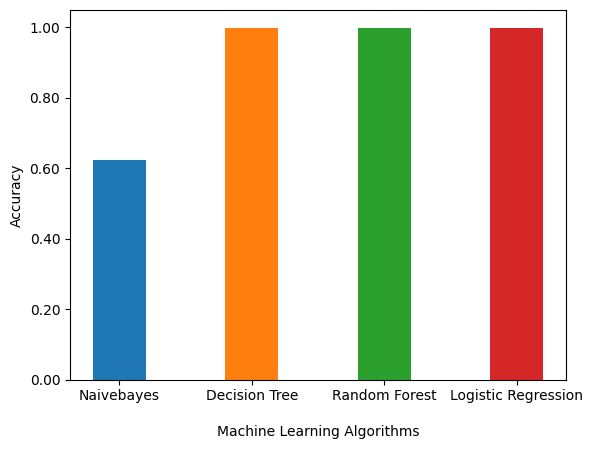

In [ ]:
from matplotlib.ticker import FormatStrFormatter
plt.figure(figsize=(8, 6))


fig, ax = plt.subplots()
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

plt.bar("Naivebayes",nbacc,width=0.4)
plt.bar("Decision Tree",dtacc,width=0.4)
plt.bar("Random Forest",rfacc,width=0.4)
plt.bar("Logistic Regression",lracc,width=0.4)
plt.xlabel("\nMachine Learning Algorithms")
plt.ylabel("Accuracy")

In [ ]:
Classifiers=["Classifiers","Logistic Regression","Random Forest","Decision Tree","Naive Bayes"]
Accuracy=["Accuracy",lracc,rfacc,dtacc,nbacc]
F1Score=["F1 Score",lrf1,rff1,dtf1,nbf1]
WeightedPrecion=["WeightedPrecision",lrweightedPrecision,rfweightedPrecision,dtweightedPrecision,nbweightedPrecision]
WeightedRecall=["WeightedRecall",lrweightedRecall,rfweightedRecall,dtweightedRecall,nbweightedRecall]


In [ ]:
from prettytable import PrettyTable

# Specify the Column Names while initializing the Table
myTable = PrettyTable(Classifiers)
# Add rows
myTable.add_row(Accuracy)
myTable.add_row(F1Score)
myTable.add_row(WeightedPrecion)
myTable.add_row(WeightedRecall)

print(myTable)

+-------------------+---------------------+--------------------+--------------------+--------------------+
|    Classifiers    | Logistic Regression |   Random Forest    |   Decision Tree    |    Naive Bayes     |
+-------------------+---------------------+--------------------+--------------------+--------------------+
|      Accuracy     |  0.9989699396813648 | 0.9993997207601547 | 0.9993863637613623 | 0.6246149059392287 |
|      F1 Score     |  0.9986184138536152 | 0.9993057848555067 | 0.9993608338435384 | 0.7676738154946054 |
| WeightedPrecision |  0.9989405016704803 | 0.9993986448036628 | 0.9993481703326312 | 0.9984928062541454 |
|   WeightedRecall  |  0.9989699396813648 | 0.9993997207601546 | 0.9993863637613624 | 0.624614905939229  |
+-------------------+---------------------+--------------------+--------------------+--------------------+


In [ ]:
Result= [Classifiers,Accuracy,F1Score,WeightedPrecion,WeightedRecall]
print(Result)
print()
for r in Result:
  print(r)

[['Classifiers', 'Logistic Regression', 'Random Forest', 'Decision Tree', 'Naive Bayes'], ['Accuracy', 0.9989699396813648, 0.9993997207601547, 0.9993863637613623, 0.6246149059392287], ['F1 Score', 0.9986184138536152, 0.9993057848555067, 0.9993608338435384, 0.7676738154946054], ['WeightedPrecision', 0.9989405016704803, 0.9993986448036628, 0.9993481703326312, 0.9984928062541454], ['WeightedRecall', 0.9989699396813648, 0.9993997207601546, 0.9993863637613624, 0.624614905939229]]

['Classifiers', 'Logistic Regression', 'Random Forest', 'Decision Tree', 'Naive Bayes']
['Accuracy', 0.9989699396813648, 0.9993997207601547, 0.9993863637613623, 0.6246149059392287]
['F1 Score', 0.9986184138536152, 0.9993057848555067, 0.9993608338435384, 0.7676738154946054]
['WeightedPrecision', 0.9989405016704803, 0.9993986448036628, 0.9993481703326312, 0.9984928062541454]
['WeightedRecall', 0.9989699396813648, 0.9993997207601546, 0.9993863637613624, 0.624614905939229]


<ipython-input-88-30db9e258c2d>:3: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


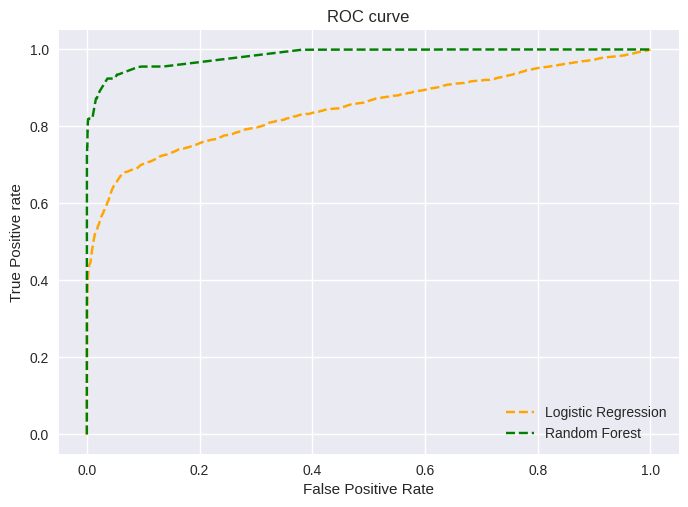

In [ ]:

#Plotting multiple ROC
# matplotlib
plt.style.use('seaborn')

# plot roc curves
plt.plot(lrroc['FPR'],lrroc['TPR'], linestyle='--',color='orange', label='Logistic Regression')
plt.plot(rfroc['FPR'],rfroc['TPR'], linestyle='--',color='green', label='Random Forest')
#plt.plot(p_fpr, p_tpr, linestyle='--', color='blue')
# title
plt.title('ROC curve')
# x label
plt.xlabel('False Positive Rate')
# y label
plt.ylabel('True Positive rate')

plt.legend(loc='best')
plt.savefig('ROC',dpi=300)
plt.show()


**Plotting ROC curves for LR using HandySpark**

In [ ]:
from pyspark.mllib.evaluation import BinaryClassificationMetrics

In [ ]:
!pip install handyspark

In [ ]:
from handyspark import *

**For LR**

In [ ]:
lrpredictions.toHandy().cols[['probability', 'prediction', 'IsFraud']]

/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:169: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:148: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


HandyColumns[probability, prediction, IsFraud]

In [ ]:
lrbcm = BinaryClassificationMetrics(lrpredictions, scoreCol='probability', labelCol='IsFraud')

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
lrbroc=lrbcm.areaUnderROC
lrbpr=lrbcm.areaUnderPR

In [ ]:
# We still can get the same metrics as the evaluator...
print("Area under ROC Curve for LR: {:.4f}".format(lrbroc))
print("Area under PR Curve for LR: {:.4f}".format(lrbpr))

Area under ROC Curve for LR: 0.8535
Area under PR Curve for LR: 0.1846


/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


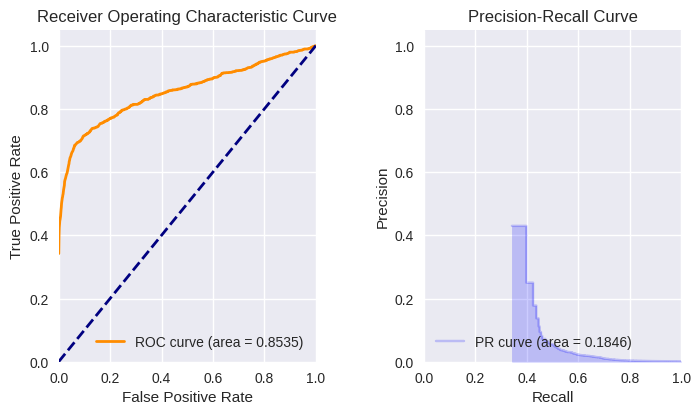

In [ ]:
# now we can PLOT both ROC and PR curves!
fig, axs = plt.subplots(1, 2, figsize=(8, 5))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)

lrbcm.plot_roc_curve(ax=axs[0])
lrbcm.plot_pr_curve(ax=axs[1])
plt.show()

**For Random Forest**

In [ ]:
rfpredictions.toHandy().cols[['probability', 'prediction', 'IsFraud']]

/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:169: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:148: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


HandyColumns[probability, prediction, IsFraud]

In [ ]:
rfbcm = BinaryClassificationMetrics(rfpredictions, scoreCol='probability', labelCol='IsFraud')

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
rfbroc=rfbcm.areaUnderROC
rfbpr=rfbcm.areaUnderPR

In [ ]:
# We still can get the same metrics as the evaluator...
print("Area under ROC Curve for RF: {:.4f}".format(rfbroc))
print("Area under PR Curve for RF: {:.4f}".format(rfbpr))

Area under ROC Curve for RF: 0.9853
Area under PR Curve for RF: 0.7678


/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


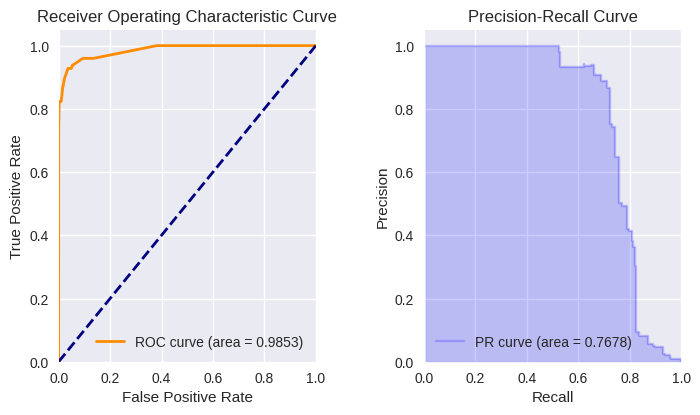

In [ ]:
# now we can PLOT both ROC and PR curves!
fig, axs = plt.subplots(1, 2, figsize=(8, 5))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)

rfbcm.plot_roc_curve(ax=axs[0])
rfbcm.plot_pr_curve(ax=axs[1])
plt.show()

**For DT**

In [ ]:
dtpredictions.toHandy().cols[['probability', 'prediction', 'IsFraud']]

/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:169: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:148: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


HandyColumns[probability, prediction, IsFraud]

In [ ]:
dtbcm = BinaryClassificationMetrics(dtpredictions, scoreCol='probability', labelCol='IsFraud')

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
dtbroc=dtbcm.areaUnderROC
dtbpr=dtbcm.areaUnderPR

In [ ]:
# We still can get the same metrics as the evaluator...
print("Area under ROC Curve for DT: {:.4f}".format(dtbroc))
print("Area under PR Curve for DT: {:.4f}".format(dtbpr))

Area under ROC Curve for DT: 0.9547
Area under PR Curve for DT: 0.6937


/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


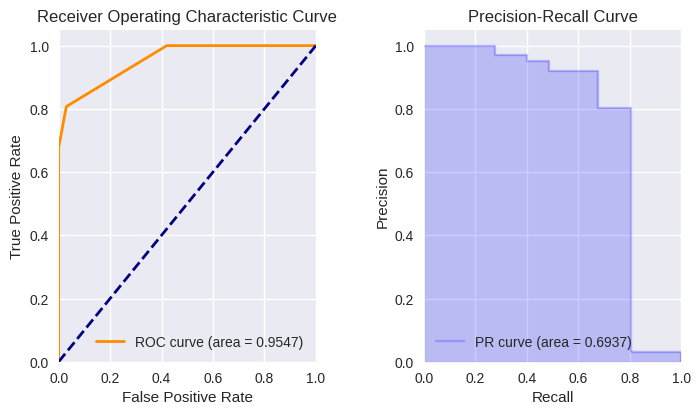

In [ ]:
# now we can PLOT both ROC and PR curves!
fig, axs = plt.subplots(1, 2, figsize=(8, 5))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)

dtbcm.plot_roc_curve(ax=axs[0])
dtbcm.plot_pr_curve(ax=axs[1])
plt.show()

**For Naive Bayes**

In [ ]:
nbpredictions.toHandy().cols[['probability', 'prediction', 'IsFraud']]

/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:169: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/dataframe.py:148: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


HandyColumns[probability, prediction, IsFraud]

In [ ]:
nbbcm = BinaryClassificationMetrics(nbpredictions, scoreCol='probability', labelCol='IsFraud')

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
nbbroc=nbbcm.areaUnderROC
nbbpr=nbbcm.areaUnderPR

In [ ]:
# We still can get the same metrics as the evaluator...
print("Area under ROC Curve for NB: {:.4f}".format(nbbroc))
print("Area under PR Curve for NB: {:.4f}".format(nbbpr))

Area under ROC Curve for NB: 0.7474
Area under PR Curve for NB: 0.0028


/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


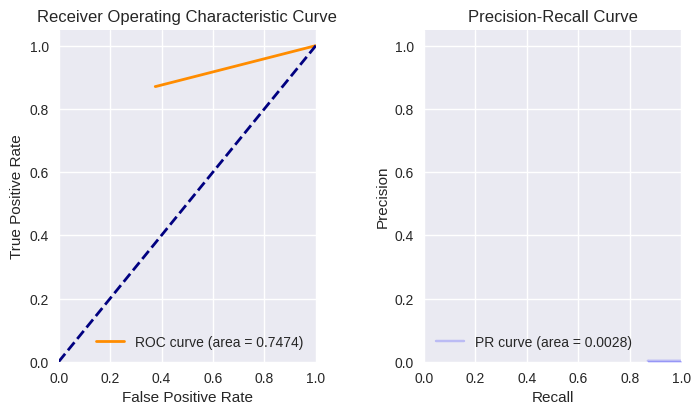

In [ ]:
# now we can PLOT both ROC and PR curves!
fig, axs = plt.subplots(1, 2, figsize=(8, 5))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)

nbbcm.plot_roc_curve(ax=axs[0])
nbbcm.plot_pr_curve(ax=axs[1])
plt.show()

Combined plot for ROC and PR curve

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  w

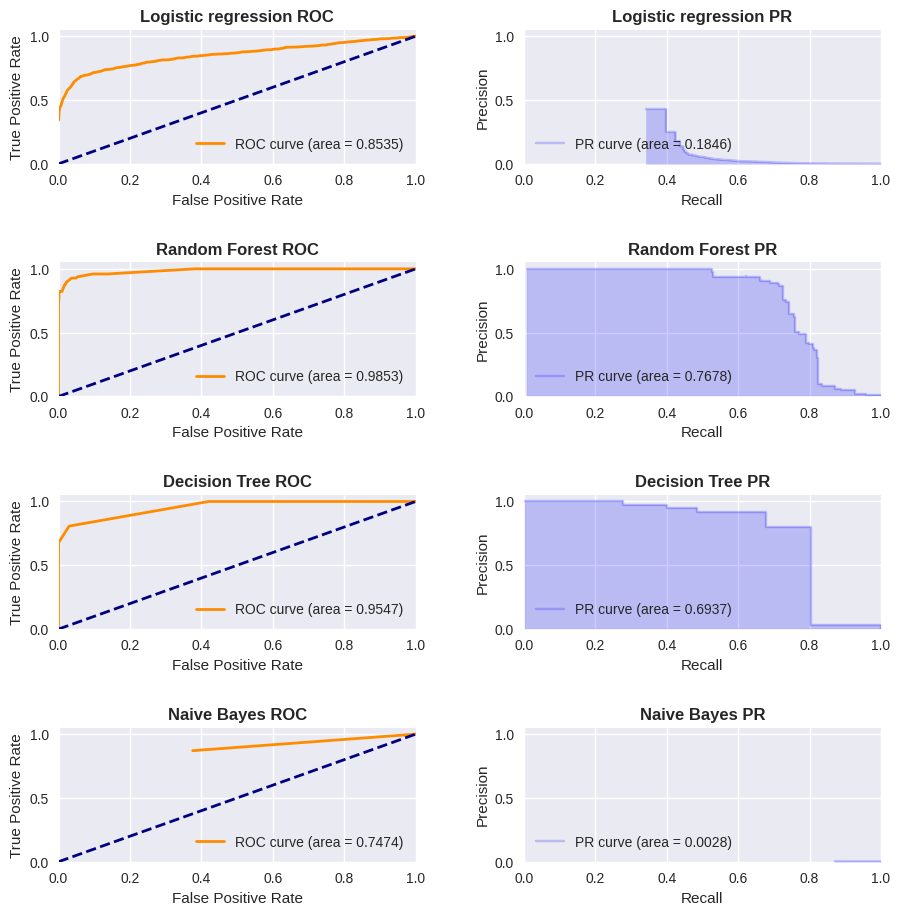

In [ ]:
# now we can PLOT both ROC and PR curves!
fig, axs = plt.subplots(4, 2, figsize=(10, 10))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)

lrbcm.plot_roc_curve(ax=axs[0][0])
lrbcm.plot_pr_curve(ax=axs[0][1])
rfbcm.plot_roc_curve(ax=axs[1][0])
rfbcm.plot_pr_curve(ax=axs[1][1])
dtbcm.plot_roc_curve(ax=axs[2][0])
dtbcm.plot_pr_curve(ax=axs[2][1])
nbbcm.plot_roc_curve(ax=axs[3][0])
nbbcm.plot_pr_curve(ax=axs[3][1])



# set the title to all subplots
axs[0, 0].set_title("Logistic regression ROC",weight='bold')
axs[1, 0].set_title("Random Forest ROC",weight='bold')
axs[2, 0].set_title("Decision Tree ROC",weight='bold')
axs[3, 0].set_title("Naive Bayes ROC",weight='bold')

axs[0, 1].set_title("Logistic regression PR",weight='bold')
axs[1, 1].set_title("Random Forest PR",weight='bold')
axs[2, 1].set_title("Decision Tree PR",weight='bold')
axs[3, 1].set_title("Naive Bayes PR",weight='bold')

plt.show()

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


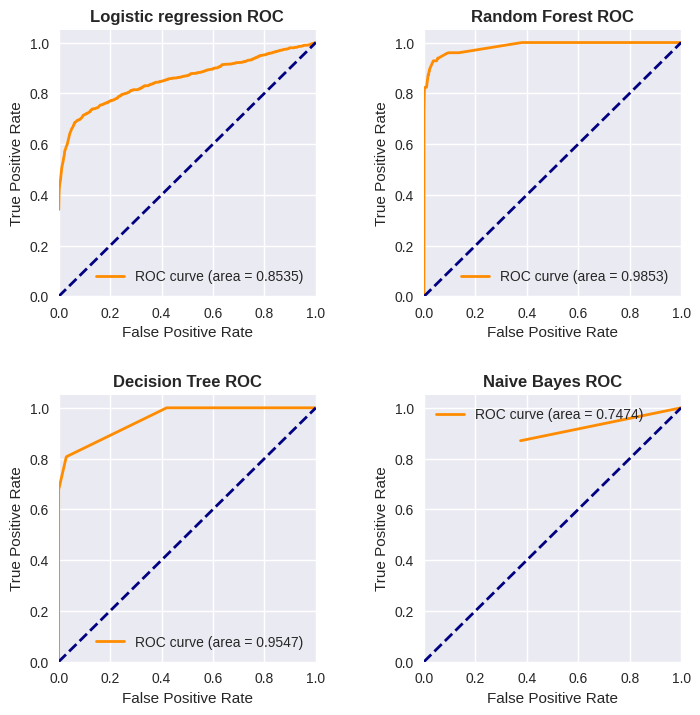

In [ ]:

fig, axs = plt.subplots(2, 2, figsize=(8, 8))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)


lrbcm.plot_roc_curve(ax=axs[0][0])

rfbcm.plot_roc_curve(ax=axs[0][1])

dtbcm.plot_roc_curve(ax=axs[1][0])

nbbcm.plot_roc_curve(ax=axs[1][1])

# set the title to all subplots
axs[0, 0].set_title("Logistic regression ROC",weight='bold')
axs[0, 1].set_title("Random Forest ROC",weight='bold')
axs[1, 0].set_title("Decision Tree ROC",weight='bold')
axs[1, 1].set_title("Naive Bayes ROC",weight='bold')



plt.legend(loc='best')
plt.savefig('ROC',dpi=300)
plt.show();

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


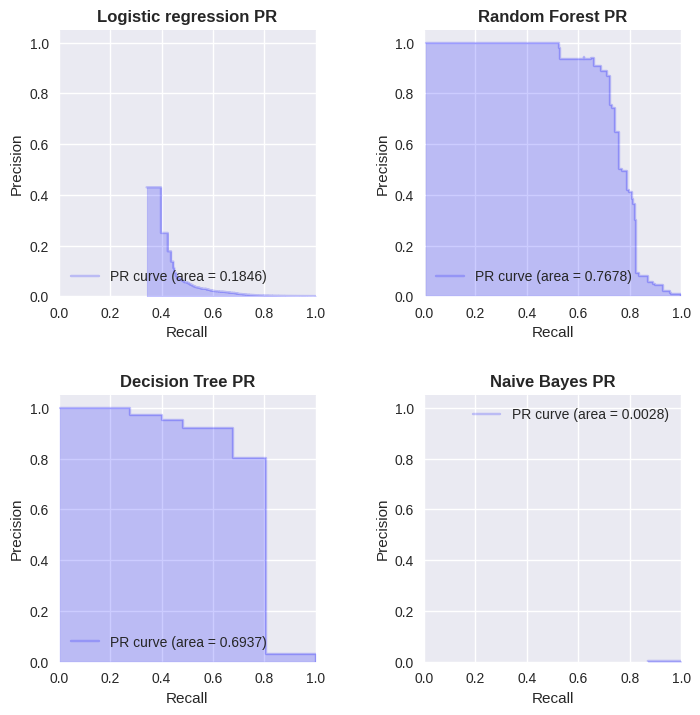

In [ ]:

fig, axs = plt.subplots(2, 2, figsize=(8, 8))

# set the spacing between subplots
# using padding
fig.tight_layout(pad=5.0)


lrbcm.plot_pr_curve(ax=axs[0][0])

rfbcm.plot_pr_curve(ax=axs[0][1])

dtbcm.plot_pr_curve(ax=axs[1][0])

nbbcm.plot_pr_curve(ax=axs[1][1])

# set the title to all subplots
axs[0, 0].set_title("Logistic regression PR",weight='bold')
axs[0, 1].set_title("Random Forest PR",weight='bold')
axs[1, 0].set_title("Decision Tree PR",weight='bold')
axs[1, 1].set_title("Naive Bayes PR",weight='bold')



plt.legend(loc='best')
plt.savefig('PR',dpi=300)
plt.show();

In [ ]:
myTable3 = PrettyTable(["Classifiers","AUC ROC","AUC PR"])
myTable3.add_row(["Logistic Regression",lrbcm.areaUnderROC,lrbcm.areaUnderPR])
myTable3.add_row(["Random Forest",rfbcm.areaUnderROC,rfbcm.areaUnderPR])
myTable3.add_row(["Decision Tree",dtbcm.areaUnderROC,dtbcm.areaUnderPR])
myTable3.add_row(["Naive Bayes",nbbcm.areaUnderROC,nbbcm.areaUnderPR])

print(myTable3)

+---------------------+--------------------+----------------------+
|     Classifiers     |      AUC ROC       |        AUC PR        |
+---------------------+--------------------+----------------------+
| Logistic Regression | 0.8535256864192262 |  0.1846448815065499  |
|    Random Forest    | 0.9853033123622894 |  0.7677619296679178  |
|    Decision Tree    | 0.9546594437163929 |  0.6936693564762447  |
|     Naive Bayes     | 0.7474339056111813 | 0.002789560726779083 |
+---------------------+--------------------+----------------------+


In [ ]:
from matplotlib.ticker import FormatStrFormatter
plt.figure(figsize=(8, 6))


fig, ax = plt.subplots()
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

plt.bar("Naivebayes",nbacc,width=0.4)
plt.bar("Decision Tree",dtacc,width=0.4)
plt.bar("Random Forest",rfacc,width=0.4)
plt.bar("Logistic Regression",lracc,width=0.4)
plt.xlabel("\nMachine Learning Algorithms")
plt.ylabel("Accuracy")

Plotting Confusion Matrix

**For LR**

In [ ]:
import pyspark.sql.functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.sql.types import FloatType

In [ ]:
from pyspark.mllib.evaluation import MulticlassMetrics

In [ ]:
# Make predicitons
lrpredictionAndLabel = lrpredictions.select("prediction","IsFraud").withColumn('label', F.col('IsFraud').cast(FloatType())).orderBy('prediction')

In [ ]:

#select only prediction and label columns
lrpredictionAndLabel = lrpredictionAndLabel.select(['prediction','label'])
lrmetrics = MulticlassMetrics(lrpredictionAndLabel.rdd.map(tuple))

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [ ]:
print(lrmetrics.confusionMatrix().toArray())

[[1.271139e+06 9.000000e+00]
 [1.302000e+03 2.910000e+02]]


In [ ]:
lrmetrics.confusionMatrix()

DenseMatrix(2, 2, [1271139.0, 1302.0, 9.0, 291.0], 0)

In [ ]:
lrFPR0=lrmetrics.falsePositiveRate(0.0)

In [ ]:
lrFPR0

0.8173258003766478

In [ ]:
lrwFPR=lrmetrics.weightedFalsePositiveRate

In [ ]:
lrwFPR

0.8163028202721184

In [ ]:
lrwTPR=lrmetrics.weightedTruePositiveRate

In [ ]:
lrwTPR

0.9989699396813648

In [ ]:
lrTPR0=lrmetrics.truePositiveRate(0.0)

In [ ]:
lrTPR0

0.9999929197858943

In [ ]:
lrprecision0=lrmetrics.precision(0.0)

In [ ]:
lrwrecall=lrmetrics.weightedRecall

In [ ]:
print(lrwrecall)
print(lrwTPR)

0.9989699396813648
0.9989699396813648


In [ ]:
lrwrecall

0.9989699396813648

In [ ]:
lrwprecision=lrmetrics.weightedPrecision

In [ ]:
lrspecificity0=1-lrFPR0

**For RF**

In [ ]:
# Make predicitons
rfpredictionAndLabel = rfpredictions.select("prediction","IsFraud").withColumn('label', F.col('IsFraud').cast(FloatType())).orderBy('prediction')

In [ ]:

#select only prediction and label columns
rfpredictionAndLabel = rfpredictionAndLabel.select(['prediction','label'])
rfmetrics = MulticlassMetrics(rfpredictionAndLabel.rdd.map(tuple))

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


**For DT**

In [ ]:
# Make predicitons
dtpredictionAndLabel = dtpredictions.select("prediction","IsFraud").withColumn('label', F.col('IsFraud').cast(FloatType())).orderBy('prediction')

In [ ]:

#select only prediction and label columns
dtpredictionAndLabel = dtpredictionAndLabel.select(['prediction','label'])
dtmetrics = MulticlassMetrics(dtpredictionAndLabel.rdd.map(tuple))

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


**For NB**

In [ ]:
# Make predicitons
nbpredictionAndLabel = nbpredictions.select("prediction","IsFraud").withColumn('label', F.col('IsFraud').cast(FloatType())).orderBy('prediction')

#select only prediction and label columns
nbpredictionAndLabel = nbpredictionAndLabel.select(['prediction','label'])
nbmetrics = MulticlassMetrics(nbpredictionAndLabel.rdd.map(tuple))

/usr/local/lib/python3.10/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


**Plotting  Metric table**

In [ ]:
WtTPR=["TPR",lrmetrics.weightedTruePositiveRate,rfmetrics.weightedTruePositiveRate,dtmetrics.weightedTruePositiveRate,nbmetrics.weightedTruePositiveRate]
WtFPR=["FPR",lrmetrics.weightedFalsePositiveRate,rfmetrics.weightedFalsePositiveRate,dtmetrics.weightedFalsePositiveRate,nbmetrics.weightedFalsePositiveRate]
wtPrecision=["Precision",lrmetrics.weightedPrecision,rfmetrics.weightedPrecision,dtmetrics.weightedPrecision,nbmetrics.weightedPrecision]
WtSpecificity=["Specificity",1-lrmetrics.weightedFalsePositiveRate,1-rfmetrics.weightedFalsePositiveRate,1-dtmetrics.weightedFalsePositiveRate,1-nbmetrics.weightedFalsePositiveRate]


In [ ]:
Classifiers=["Classifiers","Logistic Regression","Random Forest","Decision Tree","Naive Bayes"]
myTable4 = PrettyTable(Classifiers)
myTable4.add_row(WtTPR)
myTable4.add_row(WtFPR)
myTable4.add_row(wtPrecision)
myTable4.add_row(WtSpecificity)

print(myTable4)

+-------------+---------------------+--------------------+--------------------+---------------------+
| Classifiers | Logistic Regression |   Random Forest    |   Decision Tree    |     Naive Bayes     |
+-------------+---------------------+--------------------+--------------------+---------------------+
|     TPR     |  0.9989699396813648 | 0.9993997207601546 | 0.9993863637613624 |  0.624614905939229  |
|     FPR     |  0.8163028202721184 | 0.4777440436702572 | 0.3216310951087049 | 0.12962413001075732 |
|  Precision  |  0.9989405016704803 | 0.9993986448036628 | 0.9993481703326312 |  0.9984928062541454 |
| Specificity | 0.18369717972788158 | 0.5222559563297429 | 0.6783689048912951 |  0.8703758699892427 |
+-------------+---------------------+--------------------+--------------------+---------------------+


In [ ]:
rfbcm.print_confusion_matrix(.415856)

In [ ]:
dtbcm.print_confusion_matrix(.415856)

In [ ]:
nbbcm.print_confusion_matrix(.415856)

Text(11.388888888888891, 0.5, 'True value')

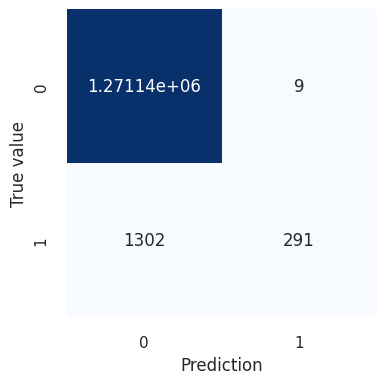

In [ ]:

sns.set (rc = {'figure.figsize':(4, 4)})
ax = sns.heatmap(lrmetrics.confusionMatrix().toArray(), cmap='Blues', annot=True, cbar=False,fmt='g')
ax.set_xlabel('Prediction')
ax.set_ylabel('True value')

Text(11.388888888888891, 0.5, 'True value')

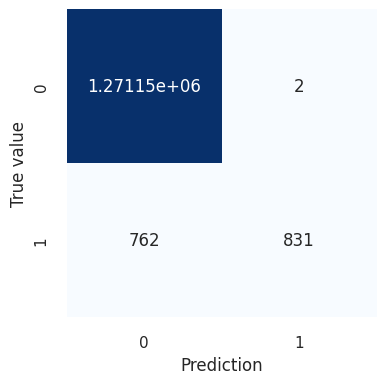

In [ ]:

sns.set (rc = {'figure.figsize':(4, 4)})
ax = sns.heatmap(rfmetrics.confusionMatrix().toArray(), cmap='Blues', annot=True, cbar=False,fmt='g')
ax.set_xlabel('Prediction')
ax.set_ylabel('True value')

Text(11.388888888888891, 0.5, 'True value')

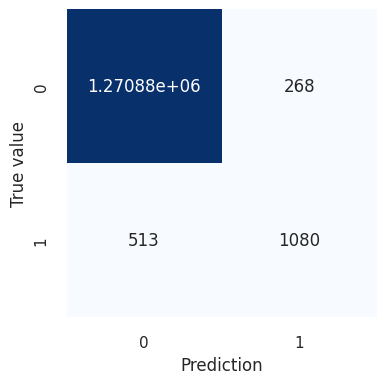

In [ ]:
sns.set (rc = {'figure.figsize':(4, 4)})
ax = sns.heatmap(dtmetrics.confusionMatrix().toArray(), cmap='Blues', annot=True, cbar=False,fmt='g')
ax.set_xlabel('Prediction')
ax.set_ylabel('True value')

Text(11.388888888888891, 0.5, 'True value')

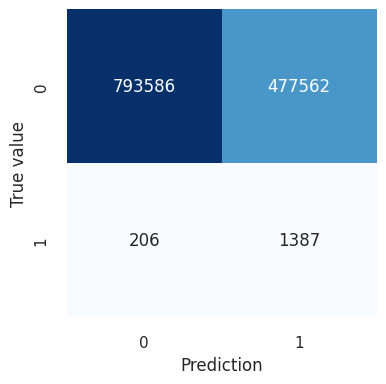

In [ ]:
sns.set (rc = {'figure.figsize':(4, 4)})
ax = sns.heatmap(nbmetrics.confusionMatrix().toArray(), cmap='Blues', annot=True, cbar=False,fmt='g')
ax.set_xlabel('Prediction')
ax.set_ylabel('True value')

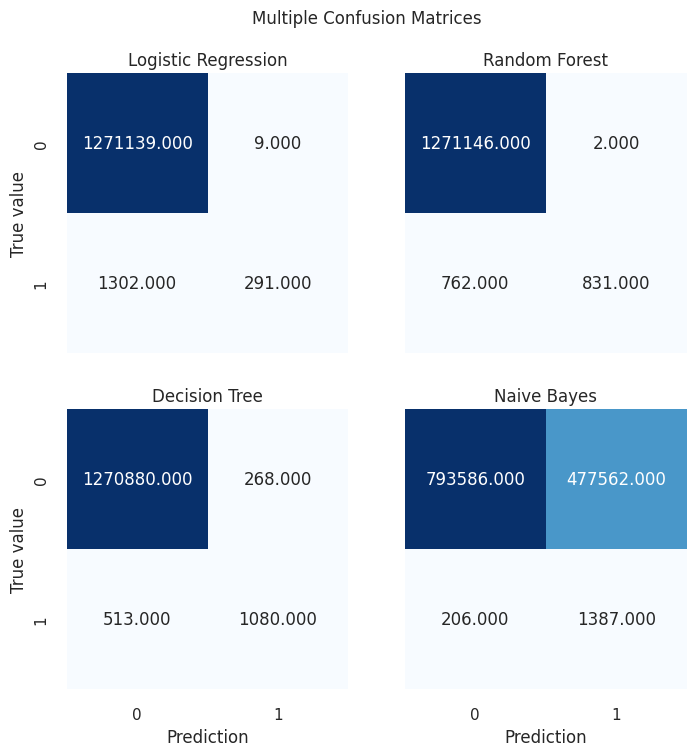

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Set formatting and styling options for the confusion matrices
title_size = 12
plt.rcParams.update({'font.size':14})
display_labels = ["0","1"]  # Customize labels of the classes
colorbar = False
cmap = "Blues"
values_format = ".3f"

sns.set (rc = {'figure.figsize':(4, 4)})
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

# Plot the first confusion matrix (Model 1) at position (0, 0)
axes[0, 0].set_title("Logistic Regression", size=title_size)
ax = sns.heatmap(lrmetrics.confusionMatrix().toArray(),ax=axes[0][0], cmap='Blues', annot=True, cbar=False,fmt='.3f')

ax.set_ylabel('True value')

# Remove x-axis labels and ticks
axes[0, 0].xaxis.set_ticklabels(['', ''])
axes[0, 0].set_xlabel('')
axes[0, 0].tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)


# Plot the second confusion matrix (Model 2) at position (0, 1)
axes[0, 1].set_title("Random Forest", size=title_size)
ax = sns.heatmap(rfmetrics.confusionMatrix().toArray(),ax=axes[0][1], cmap='Blues', annot=True, cbar=False,fmt='.3f')

ax.set_ylabel('True value')

# Remove x and y-axis labels and ticks
axes[0, 1].xaxis.set_ticklabels(['', ''])
axes[0, 1].yaxis.set_ticklabels(['', ''])
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('')
axes[0, 1].tick_params(axis='both', which='both', bottom=False, left=False)

# Plot the third confusion matrix (Model 3) at position (1, 0)
axes[1, 0].set_title("Decision Tree", size=title_size)
ax = sns.heatmap(dtmetrics.confusionMatrix().toArray(),ax=axes[1][0], cmap='Blues', annot=True, cbar=False,fmt='.3f')
ax.set_xlabel('Prediction')
ax.set_ylabel('True value')


# Plot the fourth confusion matrix (Model 4) at position (1, 1)
axes[1, 1].set_title("Naive Bayes", size=title_size)
ax = sns.heatmap(nbmetrics.confusionMatrix().toArray(),ax=axes[1][1], cmap='Blues', annot=True, cbar=False,fmt='.3f')
ax.set_xlabel('Prediction')
axes[1, 1].yaxis.set_ticklabels(['', ''])
axes[1, 1].tick_params(axis='y', which='both', bottom=True, left=False)

# Set the figure's suptitle and display the plot
fig.suptitle("Multiple Confusion Matrices", size=title_size, y=0.96)

plt.show()

**Tp, FP, TN, FN for all classifiers**

In [ ]:
lrtp=lrmetrics.confusionMatrix().toArray()[1][1]
lrtn=lrmetrics.confusionMatrix().toArray()[0][0]
lrfp=lrmetrics.confusionMatrix().toArray()[0][1]
lrfn=lrmetrics.confusionMatrix().toArray()[1][0]

rftp=rfmetrics.confusionMatrix().toArray()[1][1]
rftn=rfmetrics.confusionMatrix().toArray()[0][0]
rffp=rfmetrics.confusionMatrix().toArray()[0][1]
rffn=rfmetrics.confusionMatrix().toArray()[1][0]

dttp=dtmetrics.confusionMatrix().toArray()[1][1]
dttn=dtmetrics.confusionMatrix().toArray()[0][0]
dtfp=dtmetrics.confusionMatrix().toArray()[0][1]
dtfn=dtmetrics.confusionMatrix().toArray()[1][0]

nbtp=nbmetrics.confusionMatrix().toArray()[1][1]
nbtn=nbmetrics.confusionMatrix().toArray()[0][0]
nbfp=nbmetrics.confusionMatrix().toArray()[0][1]
nbfn=nbmetrics.confusionMatrix().toArray()[1][0]

In [ ]:
TP=["TP",lrtp,rftp,dttp,nbtp]
TN=["TN",lrtn,rftn,dttn,nbtn]
FP=["FP",lrfp,rffp,dtfp,nbfp]
FN=["FN",lrfn,rffn,dtfn,nbfn]

In [ ]:
myTable5 = PrettyTable(Classifiers)
myTable5.add_row(TP)
myTable5.add_row(TN)
myTable5.add_row(FP)
myTable5.add_row(FN)

print(myTable5)

+-------------+---------------------+---------------+---------------+-------------+
| Classifiers | Logistic Regression | Random Forest | Decision Tree | Naive Bayes |
+-------------+---------------------+---------------+---------------+-------------+
|      TP     |        291.0        |     831.0     |     1080.0    |    1387.0   |
|      TN     |      1271139.0      |   1271146.0   |   1270880.0   |   793586.0  |
|      FP     |         9.0         |      2.0      |     268.0     |   477562.0  |
|      FN     |        1302.0       |     762.0     |     513.0     |    206.0    |
+-------------+---------------------+---------------+---------------+-------------+


**Binary Classification Metric AUC and MultiEvaluator AUC**

In [ ]:
BAucRoc=["BAUC ROC ",lrbroc,rfbroc,dtbroc,nbbroc]
BAucPr=["BAUC PR",lrbpr,rfbpr,dtbpr,nbbpr]
MAucRoc=["MAUC ROC",lrmroc,rfmroc,dtmroc,nbmroc]

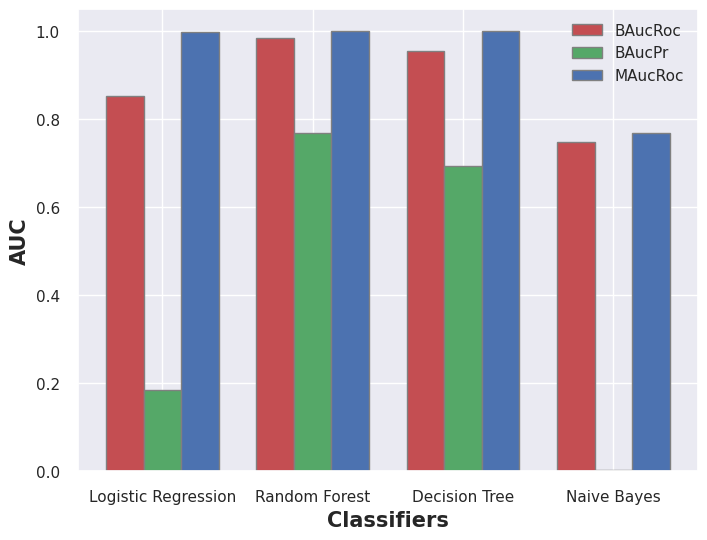

In [ ]:

# set width of bar
barWidth = 0.25
fig = plt.subplots(figsize =(8, 6))

# Set position of bar on X axis
br1 = np.arange(len(Classifiers[1:]))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]

# Make the plot
plt.bar(br1,BAucRoc[1:] , color ='r', width = barWidth,
        edgecolor ='grey', label ='BAucRoc')
plt.bar(br2, BAucPr[1:], color ='g', width = barWidth,
        edgecolor ='grey', label ='BAucPr')
plt.bar(br3,MAucRoc[1:] , color ='b', width = barWidth,
        edgecolor ='grey', label ='MAucRoc')

# Adding Xticks
plt.xlabel('Classifiers', fontweight ='bold', fontsize = 15)
plt.ylabel('AUC', fontweight ='bold', fontsize = 15)
plt.xticks([r + barWidth for r in range(len(Classifiers[1:]))],
        ['Logistic Regression','Random Forest', 'Decision Tree', 'Naive Bayes'])

plt.legend()
plt.show()

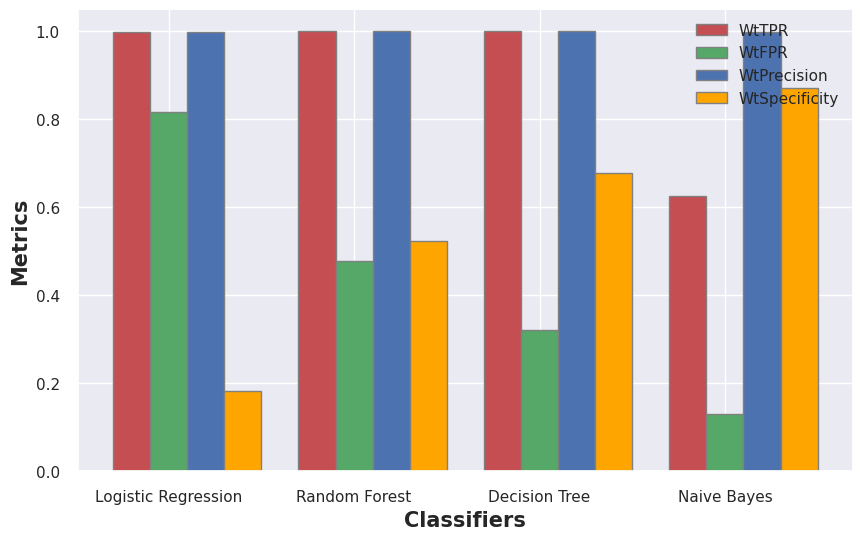

In [ ]:
WtTPR=["TPR",lrmetrics.weightedTruePositiveRate,rfmetrics.weightedTruePositiveRate,dtmetrics.weightedTruePositiveRate,nbmetrics.weightedTruePositiveRate]
WtFPR=["FPR",lrmetrics.weightedFalsePositiveRate,rfmetrics.weightedFalsePositiveRate,dtmetrics.weightedFalsePositiveRate,nbmetrics.weightedFalsePositiveRate]
wtPrecision=["Precision",lrmetrics.weightedPrecision,rfmetrics.weightedPrecision,dtmetrics.weightedPrecision,nbmetrics.weightedPrecision]
WtSpecificity=["Specificity",1-lrmetrics.weightedFalsePositiveRate,1-rfmetrics.weightedFalsePositiveRate,1-dtmetrics.weightedFalsePositiveRate,1-nbmetrics.weightedFalsePositiveRate]

# set width of bar
barWidth = 0.2
fig = plt.subplots(figsize =(10, 6))


# Set position of bar on X axis
br1 = np.arange(len(Classifiers[1:]))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]
br4 = [x + barWidth for x in br3]

# Make the plot
plt.bar(br1,WtTPR[1:] , color ='r', width = barWidth,
        edgecolor ='grey', label ='WtTPR')
plt.bar(br2, WtFPR[1:], color ='g', width = barWidth,
        edgecolor ='grey', label ='WtFPR')
plt.bar(br3,wtPrecision[1:] , color ='b', width = barWidth,
        edgecolor ='grey', label ='WtPrecision')
plt.bar(br4,WtSpecificity[1:] , color ='orange', width = barWidth,
        edgecolor ='grey', label ='WtSpecificity')

# Adding Xticks
plt.xlabel('Classifiers', fontweight ='bold', fontsize = 15)
plt.ylabel('Metrics', fontweight ='bold', fontsize = 15)
plt.xticks([r + barWidth for r in range(len(Classifiers[1:]))],
        ['Logistic Regression','Random Forest', 'Decision Tree', 'Naive Bayes'])

plt.legend()
plt.show()


**Calculating Mathew Corelation Coefficiant**

In [ ]:
import math

In [ ]:
lrmcc=(lrtp * lrtn - lrfp * lrfn) / math.sqrt((lrtp + lrfp) * (lrtp + lrfn) * (lrtn + lrfp) * (lrtn + lrfn))

rfmcc = (rftp * rftn - rffp * rffn) / math.sqrt((rftp + rffp) * (rftp + rffn) * (rftn + rffp) * (rftn + rffn))

dtmcc = (dttp * dttn - dtfp * dtfn) / math.sqrt((dttp + dtfp) * (dttp + dtfn) * (dttn + dtfp) * (dttn + dtfn))

nbmcc = (nbtp * nbtn - nbfp * nbfn) / math.sqrt((nbtp + nbfp) * (nbtp + nbfn) * (nbtn + nbfp) * (nbtn + nbfn))

In [ ]:
MCC=["MCC",lrmcc,rfmcc,dtmcc,nbmcc]

In [ ]:
myTable4 = PrettyTable(["Classifiers","BAUC ROC","BAUC PR","MAUC ROC"])
myTable4.add_row(["Logistic Regression",lrbroc,lrbpr,lrmroc])
myTable4.add_row(["Random Forest",rfbroc,rfbpr,rfmroc])
myTable4.add_row(["Decision Tree",dtbroc,dtbpr,dtmroc])
myTable4.add_row(["Naive Bayes",nbbroc,nbbpr,nbmroc])

print(myTable4)

+---------------------+--------------------+----------------------+--------------------+
|     Classifiers     |      BAUC ROC      |       BAUC PR        |      MAUC ROC      |
+---------------------+--------------------+----------------------+--------------------+
| Logistic Regression | 0.8535256864192262 |  0.1846448815065499  | 0.9986184138536152 |
|    Random Forest    | 0.9853033123622894 |  0.7677619296679178  | 0.9993057848555067 |
|    Decision Tree    | 0.9546594437163929 |  0.6936693564762447  | 0.9993608338435384 |
|     Naive Bayes     | 0.7474339056111813 | 0.002789560726779083 | 0.7676738154946054 |
+---------------------+--------------------+----------------------+--------------------+


In [ ]:
BAucRoc=["BAUC ROC ",lrbroc,rfbroc,dtbroc,nbbroc]
BAucPr=["BAUC PR",lrbpr,rfbpr,dtbpr,nbbpr]
MAucRoc=["MAUC ROC",lrmroc,rfmroc,dtmroc,nbmroc]

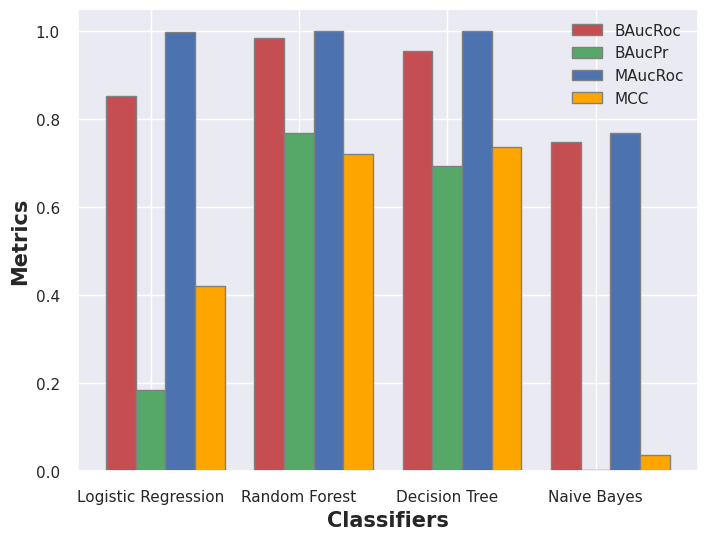

In [ ]:

# set width of bar
barWidth = 0.2
fig = plt.subplots(figsize =(8, 6))


# Set position of bar on X axis
br1 = np.arange(len(Classifiers[1:]))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]
br4 = [x + barWidth for x in br3]

# Make the plot
plt.bar(br1,BAucRoc[1:] , color ='r', width = barWidth,
        edgecolor ='grey', label ='BAucRoc')
plt.bar(br2, BAucPr[1:], color ='g', width = barWidth,
        edgecolor ='grey', label ='BAucPr')
plt.bar(br3,MAucRoc[1:] , color ='b', width = barWidth,
        edgecolor ='grey', label ='MAucRoc')
plt.bar(br4,MCC[1:] , color ='orange', width = barWidth,
        edgecolor ='grey', label ='MCC')

# Adding Xticks
plt.xlabel('Classifiers', fontweight ='bold', fontsize = 15)
plt.ylabel('Metrics', fontweight ='bold', fontsize = 15)
plt.xticks([r + barWidth for r in range(len(Classifiers[1:]))],
        ['Logistic Regression','Random Forest', 'Decision Tree', 'Naive Bayes'])

plt.legend()
plt.show()

**Calculating Balanced accuracy rate**

In [ ]:
WtTPR=["TPR",lrmetrics.weightedTruePositiveRate,rfmetrics.weightedTruePositiveRate,dtmetrics.weightedTruePositiveRate,nbmetrics.weightedTruePositiveRate]
WtFPR=["FPR",lrmetrics.weightedFalsePositiveRate,rfmetrics.weightedFalsePositiveRate,dtmetrics.weightedFalsePositiveRate,nbmetrics.weightedFalsePositiveRate]
wtPrecision=["Precision",lrmetrics.weightedPrecision,rfmetrics.weightedPrecision,dtmetrics.weightedPrecision,nbmetrics.weightedPrecision]
WtSpecificity=["Specificity",1-lrmetrics.weightedFalsePositiveRate,1-rfmetrics.weightedFalsePositiveRate,1-dtmetrics.weightedFalsePositiveRate,1-nbmetrics.weightedFalsePositiveRate]


In [ ]:
lrbar=(WtTPR[1]+WtSpecificity[1])/2

rfbar=(WtTPR[2]+WtSpecificity[2])/2

dtbar=(WtTPR[3]+WtSpecificity[3])/2

nbbar=(WtTPR[4]+WtSpecificity[4])/2

In [ ]:
BAR=["BAR",lrbar,rfbar,dtbar,nbbar]

In [ ]:
#Using Formula
lrbar1=(lrtp/(lrtp+lrfn)+lrtn/(lrtn+lrfp))/2

In [ ]:
print(lrbar1)
print(lrbar)

0.5913335597046232
0.5913335597046232


In [ ]:
myTable6 = PrettyTable(Classifiers)
myTable6.add_row(BAucRoc)
myTable6.add_row(BAucPr)
myTable6.add_row(MAucRoc)
myTable6.add_row(MCC)
myTable6.add_row(BAR)
print(myTable6)

+-------------+---------------------+--------------------+--------------------+----------------------+
| Classifiers | Logistic Regression |   Random Forest    |   Decision Tree    |     Naive Bayes      |
+-------------+---------------------+--------------------+--------------------+----------------------+
|  BAUC ROC   |  0.8535256864192262 | 0.9853033123622894 | 0.9546594437163929 |  0.7474339056111813  |
|   BAUC PR   |  0.1846448815065499 | 0.7677619296679178 | 0.6936693564762447 | 0.002789560726779083 |
|   MAUC ROC  |  0.9986184138536152 | 0.9993057848555067 | 0.9993608338435384 |  0.7676738154946054  |
|     MCC     | 0.42071391149128956 | 0.7211731266435615 |  0.73670564117238  | 0.036124767354186696 |
|     BAR     |  0.5913335597046232 | 0.7608278385449487 | 0.8388776343263287 |  0.7474953879642359  |
+-------------+---------------------+--------------------+--------------------+----------------------+


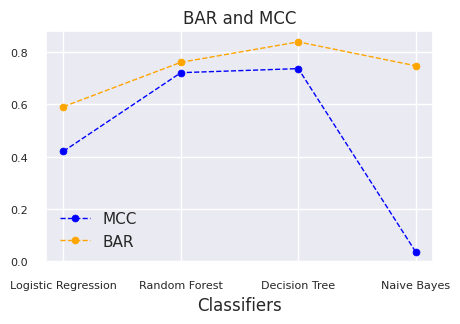

In [ ]:

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = [5, 3]
# line 1 points
x1 = Classifiers[1:]

# plotting the line 1 points
plt.plot(x1, MCC[1:], label = "MCC",marker='o', markerfacecolor='blue', markersize=5,color='blue', linestyle='dashed', linewidth = 1)

# line 2 points
x2 = Classifiers[1:]

# plotting the line 2 points
plt.plot(x2, BAR[1:], label = "BAR",marker='o', markerfacecolor='orange', markersize=5,color='orange', linestyle='dashed', linewidth = 1)

# naming the x axis
plt.xlabel('Classifiers',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

# giving a title to my graph
plt.title('BAR and MCC',fontsize=12)

# show a legend on the plot
plt.legend()

# function to show the plot
plt.show()

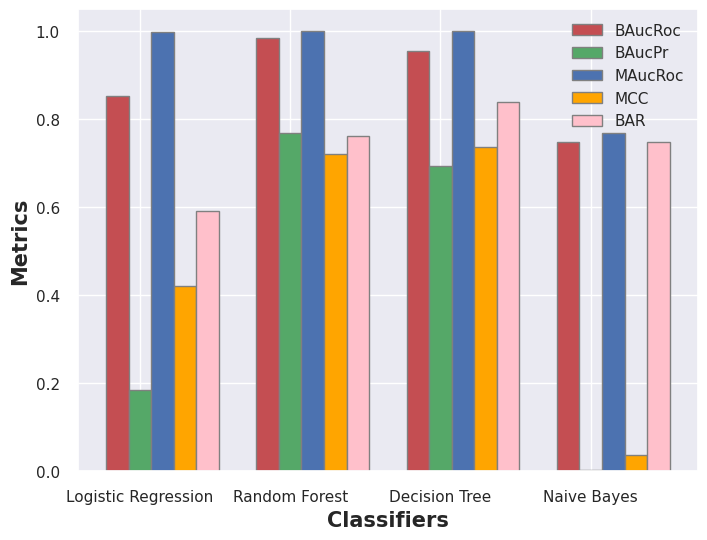

In [ ]:

# set width of bar
barWidth = 0.15
fig = plt.subplots(figsize =(8, 6))


# Set position of bar on X axis
br1 = np.arange(len(Classifiers[1:]))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]
br4 = [x + barWidth for x in br3]
br5 = [x + barWidth for x in br4]

# Make the plot
plt.bar(br1,BAucRoc[1:] , color ='r', width = barWidth,
        edgecolor ='grey', label ='BAucRoc')
plt.bar(br2, BAucPr[1:], color ='g', width = barWidth,
        edgecolor ='grey', label ='BAucPr')
plt.bar(br3,MAucRoc[1:] , color ='b', width = barWidth,
        edgecolor ='grey', label ='MAucRoc')
plt.bar(br4,MCC[1:] , color ='orange', width = barWidth,
        edgecolor ='grey', label ='MCC')
plt.bar(br5,BAR[1:] , color ='pink', width = barWidth,
        edgecolor ='grey', label ='BAR')
# Adding Xticks
plt.xlabel('Classifiers', fontweight ='bold', fontsize = 15)
plt.ylabel('Metrics', fontweight ='bold', fontsize = 15)
plt.xticks([r + barWidth for r in range(len(Classifiers[1:]))],
        ['Logistic Regression','Random Forest', 'Decision Tree', 'Naive Bayes'])

plt.legend()
plt.show()